In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import Input, Lambda, Dense, Flatten, Dropout, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2, preprocess_input
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import cv2
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

2025-10-09 15:30:55.325233: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
gpus = tf.config.list_physical_devices('GPU')
print("GPUs available to TensorFlow:", gpus)

# Detailed info (name, memory, etc.)
from tensorflow.python.client import device_lib
devices = device_lib.list_local_devices()
for d in devices:
    if d.device_type == "GPU":
        print(f"TensorFlow is using: {d.physical_device_desc}")

GPUs available to TensorFlow: []


2025-10-09 15:30:57.745891: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected
2025-10-09 15:30:57.745911: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:171] verbose logging is disabled. Rerun with verbose logging (usually --v=1 or --vmodule=cuda_diagnostics=1) to get more diagnostic output from this module
2025-10-09 15:30:57.745915: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:176] retrieving CUDA diagnostic information for host: arch
2025-10-09 15:30:57.745917: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:183] hostname: arch
2025-10-09 15:30:57.745977: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:190] libcuda reported version is: 580.95.5
2025-10-09 15:30:57.745990: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:194] kernel reported version is:

In [3]:
TRAIN_PATH = './dataset/train'
TEST_PATH = './dataset/test'

IMAGE_SIZE = [224, 224]

# Define batch size for training
BATCH_SIZE = 32

In [4]:
# Create an ImageDataGenerator for training with data augmentation
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input, # Normalizes images for MobileNetV2
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest',
    validation_split=0.2 # Use 20% of training data for validation
)

# Create an ImageDataGenerator for testing (only normalization)
test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

# Create training data generator
training_set = train_datagen.flow_from_directory(
    TRAIN_PATH,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training' # Specify this is the training subset
)

# Create validation data generator
validation_set = train_datagen.flow_from_directory(
    TRAIN_PATH, # Use the same training directory
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation' # Specify this is the validation subset
)

# Create test data generator
test_set = test_datagen.flow_from_directory(
    TEST_PATH,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False # Important: Do not shuffle test data for evaluation
)

# Get the class labels
class_labels = list(training_set.class_indices.keys())
print("Class Labels:", class_labels)

Found 12000 images belonging to 5 classes.
Found 3000 images belonging to 5 classes.
Found 5000 images belonging to 5 classes.
Class Labels: ['ALL', 'AML', 'CLL', 'CML', 'Healthy']


In [5]:
# Load the MobileNetV2 model, pre-trained on ImageNet
# include_top=False means we don't include the final classification layer
base_model = MobileNetV2(input_shape=IMAGE_SIZE + [3], weights='imagenet', include_top=False)

# Freeze the layers of the base model
for layer in base_model.layers:
    layer.trainable = False

# Add our custom layers on top of the base model
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(1024, activation='relu')(x)
x = Dropout(0.5)(x) # Add dropout for regularization
prediction = Dense(len(class_labels), activation='softmax')(x) # Final layer for 5 classes

# Create the final model
model = Model(inputs=base_model.input, outputs=prediction)

# View the model structure
model.summary()

# Compile the model
model.compile(
  loss='categorical_crossentropy',
  optimizer='adam',
  metrics=['accuracy']
)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 3,574,853 (13.64 MB)

 Trainable params: 1,316,869 (5.02 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [6]:
# Train the model
history = model.fit(
  training_set,
  validation_data=validation_set,
  epochs=10, # You can adjust the number of epochs
  steps_per_epoch=len(training_set),
  validation_steps=len(validation_set)
)

/run/media/Saksham/Saksham/Code/Projects/Leukemia/Imaging/imagingenv/lib/python3.13/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1185s 3s/step - accuracy: 0.8328 - loss: 0.4321 - val_accuracy: 0.7833 - val_loss: 0.7058
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 987s 3s/step - accuracy: 0.8959 - loss: 0.2652 - val_accuracy: 0.7857 - val_loss: 1.0824
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1156s 3s/step - accuracy: 0.9133 - loss: 0.2269 - val_accuracy: 0.7780 - val_loss: 0.9327
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 966s 3s/step - accuracy: 0.9274 - loss: 0.1993 - val_accuracy: 0.8140 - val_loss: 1.0337
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1015s 3s/step - accuracy: 0.9316 - loss: 0.1805 - val_accuracy: 0.7433 - val_loss: 1.0305
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 989s 3s/step - accuracy: 0.9357 - loss: 0.1729 - val_accuracy: 0.8100 - val_loss: 1.2119
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 959s 3s/step - accuracy: 0.9366 - loss: 0.1643 - val_accuracy: 0.8247 - val_loss: 0.9013
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 941s 3s/step - accuracy: 0.9395 - loss: 0.1645 - val_a

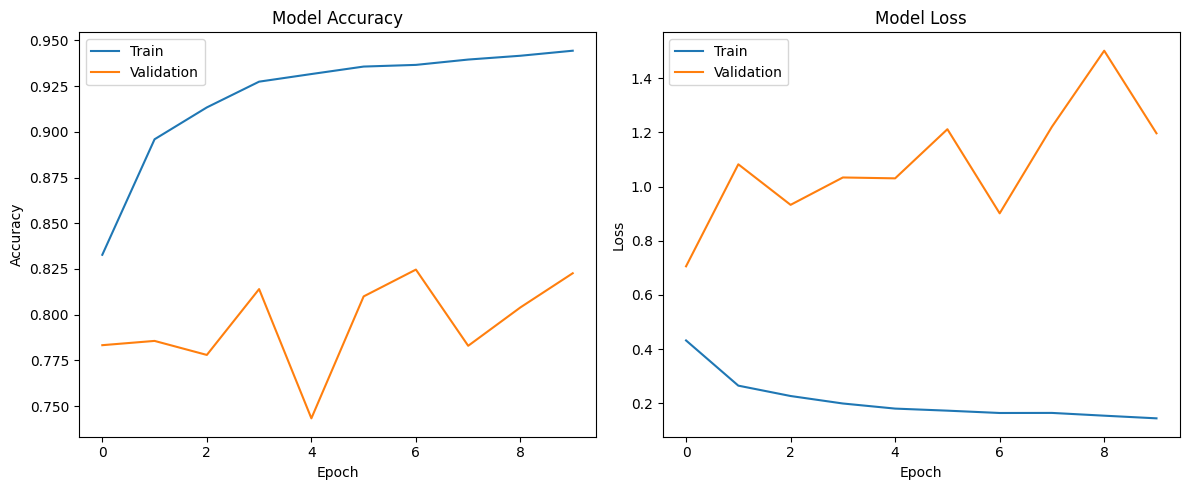

In [7]:
# Plot training & validation accuracy values
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

plt.tight_layout()
plt.show()

157/157 ━━━━━━━━━━━━━━━━━━━━ 241s 2s/step
Classification Report:

              precision    recall  f1-score   support

         ALL       0.63      0.72      0.68      1000
         AML       0.76      0.61      0.68      1000
         CLL       0.80      0.88      0.84      1000
         CML       0.94      0.93      0.93      1000
     Healthy       1.00      0.95      0.97      1000

    accuracy                           0.82      5000
   macro avg       0.82      0.82      0.82      5000
weighted avg       0.82      0.82      0.82      5000



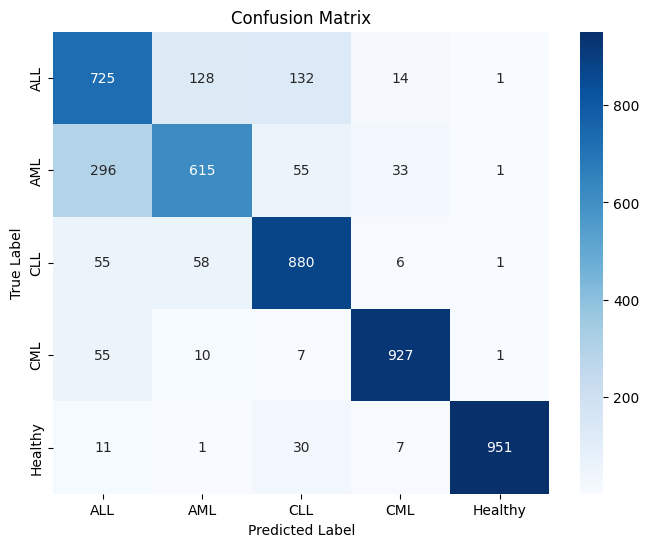

In [8]:
# Get predictions on the test set
y_pred_probs = model.predict(test_set, steps=len(test_set))
y_pred = np.argmax(y_pred_probs, axis=1)

# Get true labels
y_true = test_set.classes

# Generate and print the classification report
print("Classification Report:\n")
print(classification_report(y_true, y_pred, target_names=class_labels))

# Generate and plot the confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

In [9]:
# Save the model to a file
model.save('leukemia_subtype_detector.h5')
print("Model saved successfully!")

Model saved successfully!


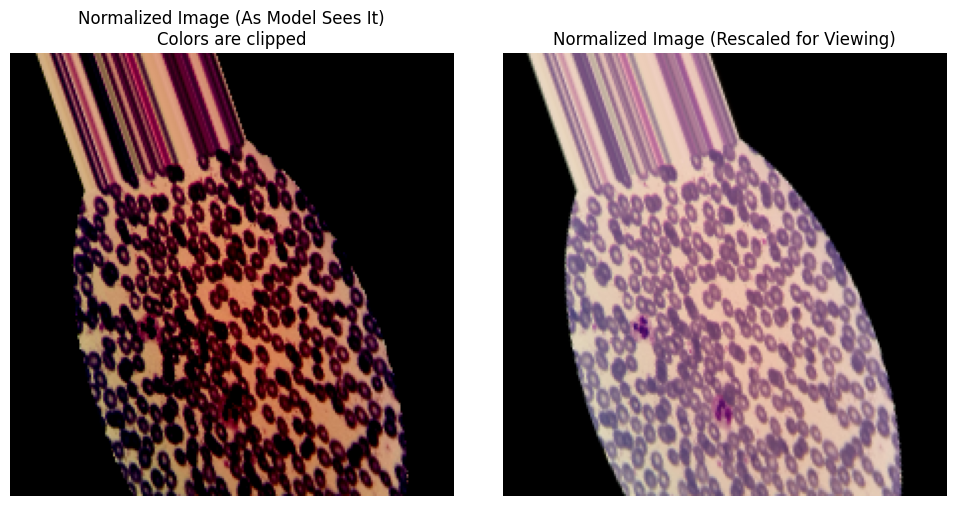

Shape of the normalized image tensor: (224, 224, 3)
Min pixel value: -1.0
Max pixel value: 0.9192474


In [10]:
# Get a batch of images from the training generator
x_batch, y_batch = next(training_set)

# Select the first image from the batch
normalized_image = x_batch[0]

# --- For Visualization Purposes Only ---
# Rescale the pixel values from [-1, 1] back to [0, 1]
# This makes the image viewable for us.
def denormalize_image(img):
  return (img + 1) / 2.0

display_image = denormalize_image(normalized_image)


# --- Plot the images ---
plt.figure(figsize=(10, 5))

# 1. Display the image as the model sees it ([-1, 1] range)
# Matplotlib will clip the negative values, so it will look weird.
plt.subplot(1, 2, 1)
plt.title("Normalized Image (As Model Sees It)\nColors are clipped")
plt.imshow(normalized_image)
plt.axis('off')

# 2. Display the rescaled image ([0, 1] range) for correct viewing
plt.subplot(1, 2, 2)
plt.title("Normalized Image (Rescaled for Viewing)")
plt.imshow(display_image)
plt.axis('off')

plt.tight_layout()
plt.show()

print("Shape of the normalized image tensor:", normalized_image.shape)
print("Min pixel value:", np.min(normalized_image))
print("Max pixel value:", np.max(normalized_image))

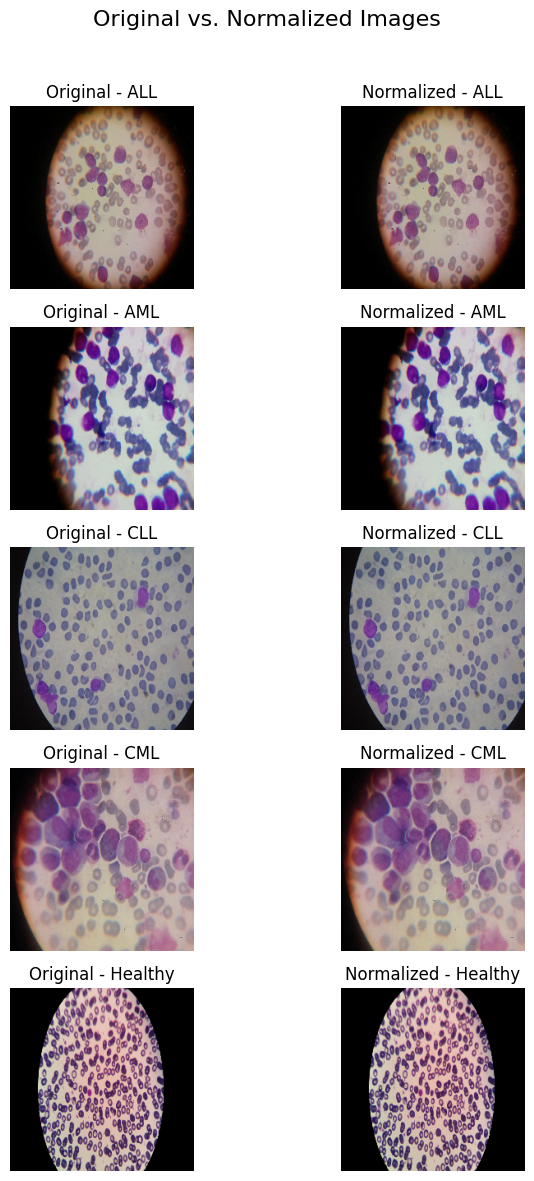

In [11]:
class_labels = sorted(os.listdir(TRAIN_PATH))

# Create a figure to display the images
fig, axes = plt.subplots(len(class_labels), 2, figsize=(8, 12))
fig.suptitle('Original vs. Normalized Images', fontsize=16)

for i, label in enumerate(class_labels):
    # Construct path to the class directory
    class_path = os.path.join(TRAIN_PATH, label)
    
    # Get the first image file in the directory
    sample_image_name = os.listdir(class_path)[0]
    sample_image_path = os.path.join(class_path, sample_image_name)
    
    # Load the original image
    original_img = image.load_img(sample_image_path, target_size=IMAGE_SIZE)
    original_img_array = image.img_to_array(original_img)
    
    # Prepare the image for normalization (create a batch of 1)
    img_for_preprocessing = np.expand_dims(original_img_array, axis=0)
    
    # Apply the normalization
    normalized_img_array = preprocess_input(img_for_preprocessing)
    
    # The output of preprocess_input is a batch, so we get the first (and only) item
    normalized_img = normalized_img_array[0]
    
    # --- For Visualization Only ---
    # Rescale the normalized image from [-1, 1] to [0, 1] so we can plot it
    display_normalized_img = (normalized_img + 1) / 2.0

    # Plot the original image
    axes[i, 0].imshow(original_img)
    axes[i, 0].set_title(f'Original - {label}')
    axes[i, 0].axis('off')
    
    # Plot the normalized image
    axes[i, 1].imshow(display_normalized_img)
    axes[i, 1].set_title(f'Normalized - {label}')
    axes[i, 1].axis('off')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()
